# Notebook de adquisición de datos — SECOP II Pereira

## Proyecto de Minería de Datos

**Pregunta de negocio:**

¿Qué patrones y posibles anomalías estadísticas se presentan en los montos, modalidades y concentración de proveedores en la contratación pública de Pereira registrada en SECOP II, y cómo esta información permite a la **Oficina de Control Interno de la Alcaldía de Pereira** pasar de auditorías aleatorias posteriores a una **priorización preventiva y focalizada de auditorías especiales** sobre los contratos con montos atípicos o contratistas hiperconcentrados antes de autorizar adiciones presupuestales o actas de liquidación?

## Objetivo del notebook

Este notebook tiene como propósito adquirir, preparar y cruzar dos fuentes oficiales de datos de SECOP II para el municipio de Pereira, Risaralda:

1. SECOP II — Procesos de Contratación.
2. SECOP II — Contratos Electrónicos.

El cruce relacional se realiza utilizando como llave confirmada el identificador del proceso de compra: la columna **`id_del_portafolio`** en la fuente de Procesos y la columna **`proceso_de_compra`** en la fuente de Contratos.

In [47]:
import pandas as pd
import requests
from io import StringIO

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [48]:
URL_PROCESOS = "https://www.datos.gov.co/resource/p6dx-8zbt.json"

params_procesos = {
    "$limit": 50000,
    "$where": "upper(ciudad_entidad) = 'PEREIRA'"
}

respuesta = requests.get(URL_PROCESOS, params=params_procesos)

print("Código de respuesta:", respuesta.status_code)

respuesta.raise_for_status()

procesos = pd.DataFrame(respuesta.json())

print("Fuente 1 - Procesos de Contratación")
print("Filas:", procesos.shape[0])
print("Columnas:", procesos.shape[1])

procesos.head()

Código de respuesta: 200
Fuente 1 - Procesos de Contratación
Filas: 50000
Columnas: 57


,entidad,nit_entidad,departamento_entidad,ciudad_entidad,ordenentidad,codigo_pci,id_del_proceso,referencia_del_proceso,ppi,id_del_portafolio,nombre_del_procedimiento,descripci_n_del_procedimiento,fase,fecha_de_publicacion_del,fecha_de_ultima_publicaci,fecha_de_publicacion_fase_3,precio_base,modalidad_de_contratacion,justificaci_n_modalidad_de,duracion,unidad_de_duracion,ciudad_de_la_unidad_de,nombre_de_la_unidad_de,proveedores_invitados,proveedores_con_invitacion,visualizaciones_del,proveedores_que_manifestaron,respuestas_al_procedimiento,respuestas_externas,conteo_de_respuestas_a_ofertas,proveedores_unicos_con,numero_de_lotes,estado_del_procedimiento,id_estado_del_procedimiento,adjudicado,id_adjudicacion,codigoproveedor,departamento_proveedor,ciudad_proveedor,valor_total_adjudicacion,nombre_del_adjudicador,nombre_del_proveedor,nit_del_proveedor_adjudicado,codigo_principal_de_categoria,estado_de_apertura_del_proceso,tipo_de_contrato,subtipo_de_contrato,categorias_adicionales,urlproceso,codigo_entidad,estado_resumen,fecha_de_publicacion_fase_2,fecha_de_recepcion_de,fecha_de_apertura_de_respuesta,fecha_de_apertura_efectiva,fecha_adjudicacion,fecha_de_publicacion
0,UNIVERSIDAD TECNOLÓGICA DE PEREIRA,891480035,Risaralda,Pereira,Territorial,Descentralizada,CO1.REQ.3293809,8085-2022,700445026,CO1.BDOS.3207380,Prestación de servicios profesionales como For...,No definido,Presentación de oferta,2022-08-30T00:00:00.000,2022-08-30T00:00:00.000,2022-08-30T00:00:00.000,13500000,Contratación régimen especial,Regla aplicable,0,día(s),Pereira,GESTIÓN DE LA CONTRATACIÓN-UNIVERSIDAD TECNOLÓ...,0,0,0,0,0,0,0,0,0,Publicado,50,No,No Adjudicado,No Definido,No Definido,No Definido,0,No Adjudicado,No Definido,No Definido,V1.80111701,Abierto,Prestación de servicios,No Definido,No definido,{'url': 'https://community.secop.gov.co/Public...,700445026,Presentación de oferta,NaN,NaN,NaN,NaN,NaN,NaN
1,AREA METROPOLITANA CENTRO OCCIDENTE,891410902,Risaralda,Pereira,Territorial,Centralizada,CO1.REQ.2659965,CD-39-2022,703244210,CO1.BDOS.2586857,PRESTACIÓN DE SERVICIOS DE APOYO A LA GESTIÓN ...,PRESTAR LOS SERVICIOS DE APOYO A LA GESTIÓN EN...,Presentación de oferta,2022-01-17T00:00:00.000,2022-01-17T00:00:00.000,2022-01-17T00:00:00.000,7200000,Contratación directa,Servicios profesionales y apoyo a la gestión,4,Mes(es),Pereira,Contratación Directa AMCO - 1,0,0,0,0,0,0,0,0,0,Seleccionado,70,No,No Adjudicado,No Definido,No Definido,No Definido,0,No Adjudicado,No Definido,No Definido,V1.80161504,Abierto,Prestación de servicios,No Definido,No definido,{'url': 'https://community.secop.gov.co/Public...,703244210,Presentación de oferta,NaN,NaN,NaN,NaN,NaN,NaN
2,CONCEJO MUNICIPAL DE PEREIRA,816002478,Risaralda,Pereira,Territorial,Centralizada,CO1.REQ.6615293,CMP-CPSAG-66-2024,705853745,CO1.BDOS.6490218,APOYO A LA GESTION,PRESTACIÓN DE SERVICIOS DE APOYO A LA GESTION ...,Presentación de oferta,2024-08-05T00:00:00.000,2024-08-05T00:00:00.000,2024-08-05T00:00:00.000,4500000,Contratación directa,Servicios profesionales y apoyo a la gestión,3,Mes(es),Pereira,CONTRATACIÓN CONCEJO MUNICIPAL DE PEREIRA,0,0,0,0,0,0,0,0,0,Seleccionado,70,No,No Adjudicado,No Definido,No Definido,No Definido,0,No Adjudicado,No Definido,No Definido,V1.83112200,Abierto,Prestación de servicios,No Definido,No definido,{'url': 'https://community.secop.gov.co/Public...,705853745,Presentación de oferta,NaN,NaN,NaN,NaN,NaN,NaN
3,MUNICIPIO DE PEREIRA- OFICIAL,891480030,Risaralda,Pereira,Territorial,Descentralizada,CO1.REQ.3542690,SMDSP-CD-7447-2022,702259557,CO1.BDOS.3451485,PRESTAR LOS SERVICIOS PROFESIONALES PARA LA EJ...,PRESTAR LOS SERVICIOS PROFESIONALES PARA LA EJ...,Presentación de oferta,2022-10-28T00:00:00.000,2022-10-28T00:00:00.000,2022-10-28T00:00:00.000,7980000,Contratación directa,Servicios profesionales y apoyo a la gestión,2,Mes(es),Pereira,SECRETARIA DESARROLLO SOCIAL Y POLÍTICO,0,0,0,0,0,0,0,0,0,Seleccionado,70,No,No Adjudicado,No Definido,No Definido,No Definido,0,No Adjudicado,No Defin

In [49]:
URL_CONTRATOS = "https://www.datos.gov.co/resource/jbjy-vk9h.json"

params_contratos = {
    "$limit": 50000,
    "$where": "upper(ciudad) = 'PEREIRA'"
}

respuesta_contratos = requests.get(
    URL_CONTRATOS,
    params=params_contratos
)

print("Código de respuesta:", respuesta_contratos.status_code)

respuesta_contratos.raise_for_status()

contratos = pd.DataFrame(respuesta_contratos.json())

print("Fuente 2 - Contratos Electrónicos")
print("Filas:", contratos.shape[0])
print("Columnas:", contratos.shape[1])

contratos.head()

Código de respuesta: 200
Fuente 2 - Contratos Electrónicos
Filas: 50000
Columnas: 95


,nombre_entidad,nit_entidad,departamento,ciudad,localizaci_n,orden,sector,rama,entidad_centralizada,proceso_de_compra,id_contrato,referencia_del_contrato,estado_contrato,codigo_de_categoria_principal,descripcion_del_proceso,tipo_de_contrato,modalidad_de_contratacion,justificacion_modalidad_de,fecha_de_firma,fecha_de_inicio_del_contrato,fecha_de_fin_del_contrato,condiciones_de_entrega,tipodocproveedor,documento_proveedor,proveedor_adjudicado,es_grupo,es_pyme,habilita_pago_adelantado,liquidaci_n,obligaci_n_ambiental,obligaciones_postconsumo,reversion,origen_de_los_recursos,destino_gasto,valor_del_contrato,valor_de_pago_adelantado,valor_facturado,valor_pendiente_de_pago,valor_pagado,valor_amortizado,valor_pendiente_de,valor_pendiente_de_ejecucion,saldo_cdp,saldo_vigencia,espostconflicto,dias_adicionados,puntos_del_acuerdo,pilares_del_acuerdo,urlproceso,nombre_representante_legal,nacionalidad_representante_legal,domicilio_representante_legal,tipo_de_identificaci_n_representante_legal,identificaci_n_representante_legal,g_nero_representante_legal,presupuesto_general_de_la_nacion_pgn,sistema_general_de_participaciones,sistema_general_de_regal_as,recursos_propios_alcald_as_gobernaciones_y_resguardos_ind_genas_,recursos_de_credito,recursos_propios,codigo_entidad,codigo_proveedor,objeto_del_contrato,duraci_n_del_contrato,nombre_del_banco,tipo_de_cuenta,n_mero_de_cuenta,el_contrato_puede_ser_prorrogado,nombre_ordenador_del_gasto,tipo_de_documento_ordenador_del_gasto,n_mero_de_documento_ordenador_del_gasto,nombre_supervisor,tipo_de_documento_supervisor,n_mero_de_documento_supervisor,nombre_ordenador_de_pago,tipo_de_documento_ordenador_de_pago,n_mero_de_documento_ordenador_de_pago,documentos_tipo,descripcion_documentos_tipo,direcci_n_de_ejecuci_n_del_contrato,criterios_de_sostenibilidad_ambiental,requisitos_ambientales_en_las_especificaciones_t_cnicas,criterios_ambientales_en_la_evaluaci_n_de_las_ofertas,obligaciones_contractuales_o_poscontractuales_a_nivel_ambiental,uso_de_etiquetado_ecol_gico,obligaciones_posconsumo,ultima_actualizacion,fecha_de_notificaci_n_de_prorrogaci_n,fecha_inicio_liquidacion,fecha_fin_liquidacion,fecha_inicio_reversi_n,fecha_fin_reversi_n,fecha_inicio_obligaciones_posconsumo,fecha_fin_obligaciones_posconsumo
0,MUNICIPIO DE PEREIRA- OFICIAL,891480030,Risaralda,Pereira,"Colombia, Risaralda , Pereira",Territorial,Servicio Público,Ejecutivo,Descentralizada,CO1.BDOS.4655229,CO1.PCCNTR.5164661,4173-2023,En ejecución,V1.80111701,PRESTAR LOS SERVICIOS DE APOYO A LA GESTION PA...,Prestación de servicios,Contratación directa,Servicios profesionales y apoyo a la gestión,2023-06-28T00:00:00.000,2023-06-30T00:00:00.000,2023-12-29T00:00:00.000,No Definido,Cédula de Ciudadanía,41106868,BEATRIZ ELENA AVILEZ TRUJILLO,No,No,No,No,No,No,No,Distribuido,Inversión,10806000,0,10806000,0,10806000,0,0,0,10806000,0,No,0,No aplica,No aplica,{'url': 'https://community.secop.gov.co/Public...,BEATRIZ ELENA AVILEZ TRUJILLO,CO,No Definido,Sin Descripcion,Sin Descripcion,Mujer,0,0,0,10806000,0,0,702259557,722465838,PRESTAR LOS SERVICIOS DE APOYO A LA GESTION PA...,6 Mes(es),BANCOLOMBIA,Ahorros,85187248235,No,ANGELA MARIA RUBIO MEJIA,Cédula de Ciudadanía,42137679,JOHN JAIRO VELASQUEZ GUERRA,Cédula de Ciudadanía,6894878,JOHN JAIRO VELASQUEZ GUERRA,Cédula de Ciudadanía,6894878,No,No definido,Cr 7 No. 18-55\nPereira\nRisaralda\nCOLOMBIA,No definido,No definido,No definido,No definido,No definido,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MEGABÚS S.A.,816007837,Risaralda,Pereira,"Colombia, Risaralda , Pereira",Territorial,Transporte,Ejecutivo,Centralizada,CO1.BDOS.3692285,CO1.PCCNTR.4367024,002-2023,terminado,V1.80111701,Prestación de servicios profesionales en el ap...,Prestación de servicios,Contratación directa,Servicios profesionales y apoyo a la gestión,2023-01-05T00:00:00.000,2023-01-05T00:00:00.000,2023-12-31T00:00:00.000,Como acordado previamente,Cédula de Ciudadanía,9955803,LUIS FERNANDO ANGEL VALLE,No,No,No,No,No,No,No,Recursos Propios,Funcionamie

In [50]:
print("Columnas de la Fuente 2:")
print(contratos.columns.tolist())

Columnas de la Fuente 2:
['nombre_entidad', 'nit_entidad', 'departamento', 'ciudad', 'localizaci_n', 'orden', 'sector', 'rama', 'entidad_centralizada', 'proceso_de_compra', 'id_contrato', 'referencia_del_contrato', 'estado_contrato', 'codigo_de_categoria_principal', 'descripcion_del_proceso', 'tipo_de_contrato', 'modalidad_de_contratacion', 'justificacion_modalidad_de', 'fecha_de_firma', 'fecha_de_inicio_del_contrato', 'fecha_de_fin_del_contrato', 'condiciones_de_entrega', 'tipodocproveedor', 'documento_proveedor', 'proveedor_adjudicado', 'es_grupo', 'es_pyme', 'habilita_pago_adelantado', 'liquidaci_n', 'obligaci_n_ambiental', 'obligaciones_postconsumo', 'reversion', 'origen_de_los_recursos', 'destino_gasto', 'valor_del_contrato', 'valor_de_pago_adelantado', 'valor_facturado', 'valor_pendiente_de_pago', 'valor_pagado', 'valor_amortizado', 'valor_pendiente_de', 'valor_pendiente_de_ejecucion', 'saldo_cdp', 'saldo_vigencia', 'espostconflicto', 'dias_adicionados', 'puntos_del_acuerdo', 'pi

In [51]:
print("========== TAMAÑO DE LAS FUENTES ==========")

print("Fuente 1 - Procesos:")
print("Filas:", procesos.shape[0])
print("Columnas:", procesos.shape[1])

print("\nFuente 2 - Contratos:")
print("Filas:", contratos.shape[0])
print("Columnas:", contratos.shape[1])

========== TAMAÑO DE LAS FUENTES ==========
Fuente 1 - Procesos:
Filas: 50000
Columnas: 57

Fuente 2 - Contratos:
Filas: 50000
Columnas: 95


In [52]:
procesos["id_del_proceso"] = (
    procesos["id_del_proceso"]
    .astype("string")
    .str.strip()
)

contratos["proceso_de_compra"] = (
    contratos["proceso_de_compra"]
    .astype("string")
    .str.strip()
)

print("Tipo en Fuente 1:", procesos["id_del_proceso"].dtype)
print("Tipo en Fuente 2:", contratos["proceso_de_compra"].dtype)

Tipo en Fuente 1: string
Tipo en Fuente 2: string


In [53]:
ids_procesos = set(
    procesos["id_del_proceso"].dropna()
)

ids_contratos = set(
    contratos["proceso_de_compra"].dropna()
)

ids_comunes = ids_procesos.intersection(ids_contratos)

print("IDs únicos en Procesos:", len(ids_procesos))
print("IDs únicos en Contratos:", len(ids_contratos))
print("IDs que aparecen en ambas fuentes:", len(ids_comunes))

IDs únicos en Procesos: 46780
IDs únicos en Contratos: 47297
IDs que aparecen en ambas fuentes: 0


In [54]:
print("Ejemplo de IDs de PROCESOS:")
print(procesos["id_del_proceso"].dropna().head(10).tolist())

print("\nEjemplo de IDs de CONTRATOS:")
print(contratos["proceso_de_compra"].dropna().head(10).tolist())

Ejemplo de IDs de PROCESOS:
['CO1.REQ.3293809', 'CO1.REQ.2659965', 'CO1.REQ.6615293', 'CO1.REQ.3542690', 'CO1.REQ.4732912', 'CO1.REQ.10616693', 'CO1.REQ.4925786', 'CO1.REQ.10495761', 'CO1.REQ.5938977', 'CO1.REQ.4650963']

Ejemplo de IDs de CONTRATOS:
['CO1.BDOS.4655229', 'CO1.BDOS.3692285', 'CO1.BDOS.4661383', 'CO1.BDOS.2404408', 'CO1.BDOS.3373288', 'CO1.BDOS.6142046', 'CO1.BDOS.9491089', 'CO1.BDOS.2337909', 'CO1.BDOS.744481', 'CO1.BDOS.3798734']


In [55]:
print("Tipos:")
print("id_del_proceso:", procesos["id_del_proceso"].dtype)
print("proceso_de_compra:", contratos["proceso_de_compra"].dtype)

Tipos:
id_del_proceso: string
proceso_de_compra: string


In [56]:
ejemplos_contratos = contratos["proceso_de_compra"].dropna().head(20)

for valor in ejemplos_contratos:
    existe = valor in set(procesos["id_del_proceso"].dropna())
    print(valor, "->", existe)

CO1.BDOS.4655229 -> False
CO1.BDOS.3692285 -> False
CO1.BDOS.4661383 -> False
CO1.BDOS.2404408 -> False
CO1.BDOS.3373288 -> False
CO1.BDOS.6142046 -> False
CO1.BDOS.9491089 -> False
CO1.BDOS.2337909 -> False
CO1.BDOS.744481 -> False
CO1.BDOS.3798734 -> False
CO1.BDOS.1879440 -> False
CO1.BDOS.7797356 -> False
CO1.BDOS.6274664 -> False
CO1.BDOS.4571118 -> False
CO1.BDOS.1660861 -> False
CO1.BDOS.3714525 -> False
CO1.BDOS.5908585 -> False
CO1.BDOS.7576754 -> False
CO1.BDOS.3876451 -> False
CO1.BDOS.5589345 -> False


In [57]:
ids_portafolio = set(
    procesos["id_del_portafolio"].dropna().astype("string").str.strip()
)

ids_proceso_compra = set(
    contratos["proceso_de_compra"].dropna().astype("string").str.strip()
)

ids_comunes_portafolio = ids_portafolio.intersection(ids_proceso_compra)

print("IDs únicos en id_del_portafolio:", len(ids_portafolio))
print("IDs únicos en proceso_de_compra:", len(ids_proceso_compra))
print("IDs en común:", len(ids_comunes_portafolio))


IDs únicos en id_del_portafolio: 46354
IDs únicos en proceso_de_compra: 47297
IDs en común: 17574


In [58]:
print("Ejemplos de coincidencias:")

for valor in list(ids_comunes_portafolio)[:10]:
    print(valor)

Ejemplos de coincidencias:
CO1.BDOS.3944364
CO1.BDOS.7331966
CO1.BDOS.5700435
CO1.BDOS.7500957
CO1.BDOS.3574168
CO1.BDOS.593345
CO1.BDOS.1508034
CO1.BDOS.8373613
CO1.BDOS.8894393
CO1.BDOS.7971629


In [59]:
print(
    contratos[
        contratos["proceso_de_compra"] == "CO1.BDOS.3207380"
    ][["proceso_de_compra", "id_contrato", "nombre_entidad"]].head()
)


Empty DataFrame
Columns: [proceso_de_compra, id_contrato, nombre_entidad]
Index: []


In [60]:
filas_procesos_antes = len(procesos)
filas_contratos_antes = len(contratos)

print("Filas de Procesos antes del cruce:", filas_procesos_antes)
print("Filas de Contratos antes del cruce:", filas_contratos_antes)

Filas de Procesos antes del cruce: 50000
Filas de Contratos antes del cruce: 50000


In [61]:
resultado = pd.merge(
    procesos,
    contratos,
    left_on="id_del_portafolio",
    right_on="proceso_de_compra",
    how="inner",
    suffixes=("_proceso", "_contrato")
)

print("========== RESULTADO DEL CRUCE ==========")
print("Filas después del merge:", resultado.shape[0])
print("Columnas después del merge:", resultado.shape[1])

resultado.head()

========== RESULTADO DEL CRUCE ==========
Filas después del merge: 22564
Columnas después del merge: 152


,entidad,nit_entidad_proceso,departamento_entidad,ciudad_entidad,ordenentidad,codigo_pci,id_del_proceso,referencia_del_proceso,ppi,id_del_portafolio,nombre_del_procedimiento,descripci_n_del_procedimiento,fase,fecha_de_publicacion_del,fecha_de_ultima_publicaci,fecha_de_publicacion_fase_3,precio_base,modalidad_de_contratacion_proceso,justificaci_n_modalidad_de,duracion,unidad_de_duracion,ciudad_de_la_unidad_de,nombre_de_la_unidad_de,proveedores_invitados,proveedores_con_invitacion,visualizaciones_del,proveedores_que_manifestaron,respuestas_al_procedimiento,respuestas_externas,conteo_de_respuestas_a_ofertas,proveedores_unicos_con,numero_de_lotes,estado_del_procedimiento,id_estado_del_procedimiento,adjudicado,id_adjudicacion,codigoproveedor,departamento_proveedor,ciudad_proveedor,valor_total_adjudicacion,nombre_del_adjudicador,nombre_del_proveedor,nit_del_proveedor_adjudicado,codigo_principal_de_categoria,estado_de_apertura_del_proceso,tipo_de_contrato_proceso,subtipo_de_contrato,categorias_adicionales,urlproceso_proceso,codigo_entidad_proceso,estado_resumen,fecha_de_publicacion_fase_2,fecha_de_recepcion_de,fecha_de_apertura_de_respuesta,fecha_de_apertura_efectiva,fecha_adjudicacion,fecha_de_publicacion,nombre_entidad,nit_entidad_contrato,departamento,ciudad,localizaci_n,orden,sector,rama,entidad_centralizada,proceso_de_compra,id_contrato,referencia_del_contrato,estado_contrato,codigo_de_categoria_principal,descripcion_del_proceso,tipo_de_contrato_contrato,modalidad_de_contratacion_contrato,justificacion_modalidad_de,fecha_de_firma,fecha_de_inicio_del_contrato,fecha_de_fin_del_contrato,condiciones_de_entrega,tipodocproveedor,documento_proveedor,proveedor_adjudicado,es_grupo,es_pyme,habilita_pago_adelantado,liquidaci_n,obligaci_n_ambiental,obligaciones_postconsumo,reversion,origen_de_los_recursos,destino_gasto,valor_del_contrato,valor_de_pago_adelantado,valor_facturado,valor_pendiente_de_pago,valor_pagado,valor_amortizado,valor_pendiente_de,valor_pendiente_de_ejecucion,saldo_cdp,saldo_vigencia,espostconflicto,dias_adicionados,puntos_del_acuerdo,pilares_del_acuerdo,urlproceso_contrato,nombre_representante_legal,nacionalidad_representante_legal,domicilio_representante_legal,tipo_de_identificaci_n_representante_legal,identificaci_n_representante_legal,g_nero_representante_legal,presupuesto_general_de_la_nacion_pgn,sistema_general_de_participaciones,sistema_general_de_regal_as,recursos_propios_alcald_as_gobernaciones_y_resguardos_ind_genas_,recursos_de_credito,recursos_propios,codigo_entidad_contrato,codigo_proveedor,objeto_del_contrato,duraci_n_del_contrato,nombre_del_banco,tipo_de_cuenta,n_mero_de_cuenta,el_contrato_puede_ser_prorrogado,nombre_ordenador_del_gasto,tipo_de_documento_ordenador_del_gasto,n_mero_de_documento_ordenador_del_gasto,nombre_supervisor,tipo_de_documento_supervisor,n_mero_de_documento_supervisor,nombre_ordenador_de_pago,tipo_de_documento_ordenador_de_pago,n_mero_de_documento_ordenador_de_pago,documentos_tipo,descripcion_documentos_tipo,direcci_n_de_ejecuci_n_del_contrato,criterios_de_sostenibilidad_ambiental,requisitos_ambientales_en_las_especificaciones_t_cnicas,criterios_ambientales_en_la_evaluaci_n_de_las_ofertas,obligaciones_contractuales_o_poscontractuales_a_nivel_ambiental,uso_de_etiquetado_ecol_gico,obligaciones_posconsumo,ultima_actualizacion,fecha_de_notificaci_n_de_prorrogaci_n,fecha_inicio_liquidacion,fecha_fin_liquidacion,fecha_inicio_reversi_n,fecha_fin_reversi_n,fecha_inicio_obligaciones_posconsumo,fecha_fin_obligaciones_posconsumo
0,GOBERNACIÓN DE RISARALDA**,891480085,Risaralda,Pereira,Territorial,Centralizada,CO1.REQ.4925786,SI-SAMC-14-2023,702280165,CO1.BDOS.4818026,ACTIVIDADES DE MANTENIMIENTO DEL BIEN DE INTER...,ACTIVIDADES DE MANTENIMIENTO DEL BIEN DE INTER...,Presentación de observaciones,2023-08-14T00:00:00.000,2023-08-14T00:00:00.000,NaN,400081342,Selección Abreviada de Menor Cuantía,Presupuesto menor al 10% de la Menor Cuantía,45,día(s),Pereira,SECRETARIA DE INFRAESTRUCTURA,0,0,98,0,0,0,

In [62]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [63]:
print("Filas Fuente 1 antes:", filas_procesos_antes)
print("Filas Fuente 2 antes:", filas_contratos_antes)
print("Filas después del merge:", len(resultado))

Filas Fuente 1 antes: 50000
Filas Fuente 2 antes: 50000
Filas después del merge: 22564


### Cruce de las fuentes

Las dos fuentes de SECOP II serán integradas utilizando como relación principal el identificador del proceso de compra. En la fuente *SECOP II – Procesos de Contratación* se utilizará la columna id_del_portafolio, mientras que en *SECOP II – Contratos Electrónicos* se utilizará la columna proceso_de_compra.

Durante la etapa de adquisición se verificó la correspondencia entre estos identificadores, encontrando 16.767 identificadores únicos en común. El cruce se realizará mediante un inner merge, conservando los registros que presenten correspondencia entre ambas fuentes.

Como resultado de la prueba realizada con los datos adquiridos, el cruce produjo 21.792 registros.

Antes del cruce se tenían 50.000 registros de cada fuente y después del cruce se obtuvieron 21.792 registros relacionados.

In [64]:
procesos_limpios = procesos[
    [
        "id_del_proceso",
        "id_del_portafolio",
        "entidad",
        "departamento_entidad",
        "ciudad_entidad",
        "fecha_de_publicacion_del",
        "modalidad_de_contratacion",
        "tipo_de_contrato",
        "precio_base",
        "valor_total_adjudicacion",
        "estado_del_procedimiento"
    ]
].copy()

In [65]:
contratos_limpios = contratos[
    [
        "proceso_de_compra",
        "id_contrato",
        "nombre_entidad",
        "fecha_de_firma",
        "fecha_de_inicio_del_contrato",
        "fecha_de_fin_del_contrato",
        "modalidad_de_contratacion",
        "tipo_de_contrato",
        "proveedor_adjudicado",
        "valor_del_contrato",
        "estado_contrato"
    ]
].copy()

In [66]:
dataset_final = pd.merge(
    procesos_limpios,
    contratos_limpios,
    left_on="id_del_portafolio",
    right_on="proceso_de_compra",
    how="inner",
    suffixes=("_proceso", "_contrato")
)

print("========== DATASET FINAL ==========")
print("Filas:", dataset_final.shape[0])
print("Columnas:", dataset_final.shape[1])

dataset_final.head()

========== DATASET FINAL ==========
Filas: 22564
Columnas: 22


,id_del_proceso,id_del_portafolio,entidad,departamento_entidad,ciudad_entidad,fecha_de_publicacion_del,modalidad_de_contratacion_proceso,tipo_de_contrato_proceso,precio_base,valor_total_adjudicacion,estado_del_procedimiento,proceso_de_compra,id_contrato,nombre_entidad,fecha_de_firma,fecha_de_inicio_del_contrato,fecha_de_fin_del_contrato,modalidad_de_contratacion_contrato,tipo_de_contrato_contrato,proveedor_adjudicado,valor_del_contrato,estado_contrato
0,CO1.REQ.4925786,CO1.BDOS.4818026,GOBERNACIÓN DE RISARALDA**,Risaralda,Pereira,2023-08-14T00:00:00.000,Selección Abreviada de Menor Cuantía,Obra,400081342,0,Evaluación,CO1.BDOS.4818026,CO1.PCCNTR.5428644,GOBERNACIÓN DE RISARALDA**,2023-10-11T00:00:00.000,2023-11-21T00:00:00.000,2024-12-14T00:00:00.000,Selección Abreviada de Menor Cuantía,Obra,INGENIERIA Y PROYECTOS SOSTENIBLES SAS,436272918,Modificado
1,CO1.REQ.1377798,CO1.BDOS.1298792,MUNICIPIO DE PEREIRA- OFICIAL,Risaralda,Pereira,2020-07-14T00:00:00.000,Licitación pública Obra Publica,Obra,4449770565,2473376817,Seleccionado,CO1.BDOS.1298792,CO1.PCCNTR.1930806,MUNICIPIO DE PEREIRA- OFICIAL,2020-10-22T00:00:00.000,2020-11-03T00:00:00.000,2021-07-01T00:00:00.000,Licitación pública Obra Publica,Obra,CONSORCIO SANTA LUCIA 3,1682572293,En ejecución
2,CO1.REQ.1377798,CO1.BDOS.1298792,MUNICIPIO DE PEREIRA- OFICIAL,Risaralda,Pereira,2020-07-14T00:00:00.000,Licitación pública Obra Publica,Obra,4449770565,2473376817,Seleccionado,CO1.BDOS.1298792,CO1.PCCNTR.1904406,MUNICIPIO DE PEREIRA- OFICIAL,2020-10-21T00:00:00.000,2020-10-22T00:00:00.000,2020-12-31T00:00:00.000,Licitación pública Obra Publica,Obra,CONSORCIO SANTA LUCIA 3,1916484569,terminado
3,CO1.REQ.1377798,CO1.BDOS.1298792,MUNICIPIO DE PEREIRA- OFICIAL,Risaralda,Pereira,2020-07-14T00:00:00.000,Licitación pública Obra Publica,Obra,4449770565,2473376817,Seleccionado,CO1.BDOS.1298792,CO1.PCCNTR.1904503,MUNICIPIO DE PEREIRA- OFICIAL,2020-10-21T00:00:00.000,2020-10-22T00:00:00.000,2020-12-10T00:00:00.000,Licitación pública Obra Publica,Obra,CONSORCIO PROINGE 1,2473376817,terminado
4,CO1.REQ.3914347,CO1.BDOS.3819090,PERSONERIA MUNICIPAL DE PEREIRA,Risaralda,Pereira,2023-01-23T00:00:00.000,Contratación directa,Prestación de servicios,14400000,0,Seleccionado,CO1.BDOS.3819090,CO1.PCCNTR.4459047,PERSONERIA MUNICIPAL DE PEREIRA,2023-01-26T00:00:00.000,2023-02-01T00:00:00.000,2023-05-31T00:00:00.000,Contratación directa,Prestación de servicios,MATEO LOPEZ CHICA,14400000,terminado


In [67]:
print(dataset_final.columns.tolist())

['id_del_proceso', 'id_del_portafolio', 'entidad', 'departamento_entidad', 'ciudad_entidad', 'fecha_de_publicacion_del', 'modalidad_de_contratacion_proceso', 'tipo_de_contrato_proceso', 'precio_base', 'valor_total_adjudicacion', 'estado_del_procedimiento', 'proceso_de_compra', 'id_contrato', 'nombre_entidad', 'fecha_de_firma', 'fecha_de_inicio_del_contrato', 'fecha_de_fin_del_contrato', 'modalidad_de_contratacion_contrato', 'tipo_de_contrato_contrato', 'proveedor_adjudicado', 'valor_del_contrato', 'estado_contrato']


In [68]:
print(dataset_final.dtypes)

id_del_proceso                        string[python]
id_del_portafolio                             object
entidad                                       object
departamento_entidad                          object
ciudad_entidad                                object
fecha_de_publicacion_del                      object
modalidad_de_contratacion_proceso             object
tipo_de_contrato_proceso                      object
precio_base                                   object
valor_total_adjudicacion                      object
estado_del_procedimiento                      object
proceso_de_compra                     string[python]
id_contrato                                   object
nombre_entidad                                object
fecha_de_firma                                object
fecha_de_inicio_del_contrato                  object
fecha_de_fin_del_contrato                     object
modalidad_de_contratacion_contrato            object
tipo_de_contrato_contrato                     

In [69]:
print(dataset_final.isna().sum())

id_del_proceso                          0
id_del_portafolio                       0
entidad                                 0
departamento_entidad                    0
ciudad_entidad                          0
fecha_de_publicacion_del               87
modalidad_de_contratacion_proceso       0
tipo_de_contrato_proceso                0
precio_base                             0
valor_total_adjudicacion                0
estado_del_procedimiento                0
proceso_de_compra                       0
id_contrato                             0
nombre_entidad                          0
fecha_de_firma                        219
fecha_de_inicio_del_contrato          665
fecha_de_fin_del_contrato               0
modalidad_de_contratacion_contrato      0
tipo_de_contrato_contrato               0
proveedor_adjudicado                    0
valor_del_contrato                      0
estado_contrato                         0
dtype: int64


## Revisión inicial de calidad de los datos

Después de realizar el cruce de las fuentes se revisaron los tipos de datos y los valores faltantes del dataset resultante.

El dataset cruzado contiene 21.792 registros y 22 columnas.

La mayoría de las columnas no presentan valores faltantes. Sin embargo, se identificaron valores faltantes principalmente en las variables relacionadas con las fechas de los contratos:

* `fecha_de_publicacion_del`: 78 valores faltantes.
* `fecha_de_firma`: 1.741 valores faltantes.
* `fecha_de_inicio_del_contrato`: 2.148 valores faltantes.
* `fecha_de_fin_del_contrato`: 287 valores faltantes.

Estos valores faltantes se conservarán en esta etapa de adquisición y serán considerados posteriormente durante la preparación y el análisis de los datos. No se eliminarán automáticamente porque la ausencia de una fecha puede corresponder a diferentes estados o situaciones del registro y debe analizarse antes de decidir cómo tratarla.


In [70]:
diccionario_datos = pd.DataFrame([
    {
        "columna": "id_del_proceso",
        "tipo_de_dato": "string[python]",
        "significado": "Identificador del proceso de contratación.",
        "fuente": "SECOP II - Procesos de Contratación"
    },
    {
        "columna": "id_del_portafolio",
        "tipo_de_dato": "object",
        "significado": "Identificador del portafolio asociado al proceso y utilizado como llave para relacionar las dos fuentes.",
        "fuente": "SECOP II - Procesos de Contratación"
    },
    {
        "columna": "entidad",
        "tipo_de_dato": "object",
        "significado": "Nombre de la entidad que publica el proceso de contratación.",
        "fuente": "SECOP II - Procesos de Contratación"
    },
    {
        "columna": "departamento_entidad",
        "tipo_de_dato": "object",
        "significado": "Departamento donde está registrada la entidad contratante.",
        "fuente": "SECOP II - Procesos de Contratación"
    },
    {
        "columna": "ciudad_entidad",
        "tipo_de_dato": "object",
        "significado": "Ciudad donde está registrada la entidad contratante.",
        "fuente": "SECOP II - Procesos de Contratación"
    },
    {
        "columna": "fecha_de_publicacion_del",
        "tipo_de_dato": "object",
        "significado": "Fecha de publicación del proceso de contratación.",
        "fuente": "SECOP II - Procesos de Contratación"
    },
    {
        "columna": "modalidad_de_contratacion_proceso",
        "tipo_de_dato": "object",
        "significado": "Modalidad mediante la cual se desarrolla el proceso de contratación.",
        "fuente": "SECOP II - Procesos de Contratación"
    },
    {
        "columna": "tipo_de_contrato_proceso",
        "tipo_de_dato": "object",
        "significado": "Tipo de contrato registrado en el proceso.",
        "fuente": "SECOP II - Procesos de Contratación"
    },
    {
        "columna": "precio_base",
        "tipo_de_dato": "object",
        "significado": "Valor base registrado para el proceso de contratación.",
        "fuente": "SECOP II - Procesos de Contratación"
    },
    {
        "columna": "valor_total_adjudicacion",
        "tipo_de_dato": "object",
        "significado": "Valor total adjudicado asociado al proceso.",
        "fuente": "SECOP II - Procesos de Contratación"
    },
    {
        "columna": "estado_del_procedimiento",
        "tipo_de_dato": "object",
        "significado": "Estado registrado del procedimiento de contratación.",
        "fuente": "SECOP II - Procesos de Contratación"
    },
    {
        "columna": "proceso_de_compra",
        "tipo_de_dato": "string[python]",
        "significado": "Identificador del proceso de compra asociado al contrato. Se utiliza como contraparte de la llave de cruce.",
        "fuente": "SECOP II - Contratos Electrónicos"
    },
    {
        "columna": "id_contrato",
        "tipo_de_dato": "object",
        "significado": "Identificador del contrato electrónico.",
        "fuente": "SECOP II - Contratos Electrónicos"
    },
    {
        "columna": "nombre_entidad",
        "tipo_de_dato": "object",
        "significado": "Nombre de la entidad asociada al contrato.",
        "fuente": "SECOP II - Contratos Electrónicos"
    },
    {
        "columna": "fecha_de_firma",
        "tipo_de_dato": "object",
        "significado": "Fecha registrada de firma del contrato.",
        "fuente": "SECOP II - Contratos Electrónicos"
    },
    {
        "columna": "fecha_de_inicio_del_contrato",
        "tipo_de_dato": "object",
        "significado": "Fecha registrada de inicio del contrato.",
        "fuente": "SECOP II - Contratos Electrónicos"
    },
    {
        "columna": "fecha_de_fin_del_contrato",
        "tipo_de_dato": "object",
        "significado": "Fecha registrada de finalización del contrato.",
        "fuente": "SECOP II - Contratos Electrónicos"
    },
    {
        "columna": "modalidad_de_contratacion_contrato",
        "tipo_de_dato": "object",
        "significado": "Modalidad de contratación registrada en el contrato.",
        "fuente": "SECOP II - Contratos Electrónicos"
    },
    {
        "columna": "tipo_de_contrato_contrato",
        "tipo_de_dato": "object",
        "significado": "Tipo de contrato registrado en la fuente de contratos.",
        "fuente": "SECOP II - Contratos Electrónicos"
    },
    {
        "columna": "proveedor_adjudicado",
        "tipo_de_dato": "object",
        "significado": "Proveedor al que fue adjudicado el contrato.",
        "fuente": "SECOP II - Contratos Electrónicos"
    },
    {
        "columna": "valor_del_contrato",
        "tipo_de_dato": "object",
        "significado": "Valor registrado del contrato.",
        "fuente": "SECOP II - Contratos Electrónicos"
    },
    {
        "columna": "estado_contrato",
        "tipo_de_dato": "object",
        "significado": "Estado registrado del contrato.",
        "fuente": "SECOP II - Contratos Electrónicos"
    }
])

diccionario_datos

,columna,tipo_de_dato,significado,fuente
0,id_del_proceso,string[python],Identificador del proceso de contratación.,SECOP II - Procesos de Contratación
1,id_del_portafolio,object,Identificador del portafolio asociado al proce...,SECOP II - Procesos de Contratación
2,entidad,object,Nombre de la entidad que publica el proceso de...,SECOP II - Procesos de Contratación
3,departamento_entidad,object,Departamento donde está registrada la entidad ...,SECOP II - Procesos de Contratación
4,ciudad_entidad,object,Ciudad donde está registrada la entidad contra...,SECOP II - Procesos de Contratación
5,fecha_de_publicacion_del,object,Fecha de publicación del proceso de contratación.,SECOP II - Procesos de Contratación
6,modalidad_de_contratacion_proceso,object,Modalidad mediante la cual se desarrolla el pr...,SECOP II - Procesos de Contratación
7,tipo_de_contrato_proceso,object,Tipo de contrato registrado en el proceso.,SECOP II - Procesos de Contratación
8,precio_base,object,Valor base registrado para el proceso de contr...,SECOP II - Procesos de Contratación
9,valor_total_adjudicacion,object,Valor total adjudicado asociado al proceso.,SECOP II - Procesos de Contratación


In [71]:
print("Columnas del dataset final:", len(dataset_final.columns))
print("Filas del dataset final:", len(dataset_final))

print("Columnas documentadas:", len(diccionario_datos))

if set(dataset_final.columns) == set(diccionario_datos["columna"]):
    print("✓ Todas las columnas del dataset final están documentadas.")
else:
    print(" Hay columnas que faltan o sobran en el diccionario.")

Columnas del dataset final: 22
Filas del dataset final: 22564
Columnas documentadas: 22
✓ Todas las columnas del dataset final están documentadas.


In [72]:
diccionario_datos.to_csv(
    "diccionario_datos_secop_pereira.csv",
    index=False,
    encoding="utf-8-sig"
)

print("✓ Diccionario guardado correctamente.")

✓ Diccionario guardado correctamente.


In [73]:
dataset_final.to_csv(
    "dataset_secop_pereira_cruzado.csv",
    index=False,
    encoding="utf-8-sig"
)

print("✓ Dataset cruzado guardado correctamente.")

✓ Dataset cruzado guardado correctamente.


In [74]:
import os
from google.colab import files
print("Archivos CSV encontrados:")
csvs = [f for f in os.listdir('.') if f.endswith('.csv')]
print(csvs)

if "diccionario_datos_secop_pereira.csv" in csvs:
    files.download("diccionario_datos_secop_pereira.csv")
else:
    print("El archivo 'diccionario_datos_secop_pereira.csv' no existe aún.")

if "dataset_secop_pereira_cruzado.csv" in csvs:
    files.download("dataset_secop_pereira_cruzado.csv")
else:
    print("El archivo 'dataset_secop_pereira_cruzado.csv' no existe aún.")

Archivos CSV encontrados:
['diccionario_datos_secop_pereira.csv', 'dataset_secop_pereira_cruzado.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [75]:
print("Tamaño del dataset:", dataset_final.shape)

display(dataset_final.dtypes)

display(dataset_final.head())


Tamaño del dataset: (22564, 22)


,0
id_del_proceso,string[python]
id_del_portafolio,object
entidad,object
departamento_entidad,object
ciudad_entidad,object
fecha_de_publicacion_del,object
modalidad_de_contratacion_proceso,object
tipo_de_contrato_proceso,object
precio_base,object
valor_total_adjudicacion,object


,id_del_proceso,id_del_portafolio,entidad,departamento_entidad,ciudad_entidad,fecha_de_publicacion_del,modalidad_de_contratacion_proceso,tipo_de_contrato_proceso,precio_base,valor_total_adjudicacion,estado_del_procedimiento,proceso_de_compra,id_contrato,nombre_entidad,fecha_de_firma,fecha_de_inicio_del_contrato,fecha_de_fin_del_contrato,modalidad_de_contratacion_contrato,tipo_de_contrato_contrato,proveedor_adjudicado,valor_del_contrato,estado_contrato
0,CO1.REQ.4925786,CO1.BDOS.4818026,GOBERNACIÓN DE RISARALDA**,Risaralda,Pereira,2023-08-14T00:00:00.000,Selección Abreviada de Menor Cuantía,Obra,400081342,0,Evaluación,CO1.BDOS.4818026,CO1.PCCNTR.5428644,GOBERNACIÓN DE RISARALDA**,2023-10-11T00:00:00.000,2023-11-21T00:00:00.000,2024-12-14T00:00:00.000,Selección Abreviada de Menor Cuantía,Obra,INGENIERIA Y PROYECTOS SOSTENIBLES SAS,436272918,Modificado
1,CO1.REQ.1377798,CO1.BDOS.1298792,MUNICIPIO DE PEREIRA- OFICIAL,Risaralda,Pereira,2020-07-14T00:00:00.000,Licitación pública Obra Publica,Obra,4449770565,2473376817,Seleccionado,CO1.BDOS.1298792,CO1.PCCNTR.1930806,MUNICIPIO DE PEREIRA- OFICIAL,2020-10-22T00:00:00.000,2020-11-03T00:00:00.000,2021-07-01T00:00:00.000,Licitación pública Obra Publica,Obra,CONSORCIO SANTA LUCIA 3,1682572293,En ejecución
2,CO1.REQ.1377798,CO1.BDOS.1298792,MUNICIPIO DE PEREIRA- OFICIAL,Risaralda,Pereira,2020-07-14T00:00:00.000,Licitación pública Obra Publica,Obra,4449770565,2473376817,Seleccionado,CO1.BDOS.1298792,CO1.PCCNTR.1904406,MUNICIPIO DE PEREIRA- OFICIAL,2020-10-21T00:00:00.000,2020-10-22T00:00:00.000,2020-12-31T00:00:00.000,Licitación pública Obra Publica,Obra,CONSORCIO SANTA LUCIA 3,1916484569,terminado
3,CO1.REQ.1377798,CO1.BDOS.1298792,MUNICIPIO DE PEREIRA- OFICIAL,Risaralda,Pereira,2020-07-14T00:00:00.000,Licitación pública Obra Publica,Obra,4449770565,2473376817,Seleccionado,CO1.BDOS.1298792,CO1.PCCNTR.1904503,MUNICIPIO DE PEREIRA- OFICIAL,2020-10-21T00:00:00.000,2020-10-22T00:00:00.000,2020-12-10T00:00:00.000,Licitación pública Obra Publica,Obra,CONSORCIO PROINGE 1,2473376817,terminado
4,CO1.REQ.3914347,CO1.BDOS.3819090,PERSONERIA MUNICIPAL DE PEREIRA,Risaralda,Pereira,2023-01-23T00:00:00.000,Contratación directa,Prestación de servicios,14400000,0,Seleccionado,CO1.BDOS.3819090,CO1.PCCNTR.4459047,PERSONERIA MUNICIPAL DE PEREIRA,2023-01-26T00:00:00.000,2023-02-01T00:00:00.000,2023-05-31T00:00:00.000,Contratación directa,Prestación de servicios,MATEO LOPEZ CHICA,14400000,terminado


In [76]:
%whos

Variable                      Type         Data/Info
----------------------------------------------------
StringIO                      type         <class '_io.StringIO'>
URL_CONTRATOS                 str          https://www.datos.gov.co/resource/jbjy-vk9h.json
URL_PROCESOS                  str          https://www.datos.gov.co/resource/p6dx-8zbt.json
casos_revision                DataFrame            id_del_proceso id<...>[18241 rows x 23 columns]
ceros_adjudicacion            DataFrame            id_del_proceso id<...>[18338 rows x 23 columns]
columna                       str          valor_del_contrato
columnas_fecha                list         n=4
columnas_valor                list         n=3
contratos                     DataFrame                          nom<...>[50000 rows x 95 columns]
contratos_limpios             DataFrame          proceso_de_compra  <...>[50000 rows x 11 columns]
csvs                          list         n=2
dataset_final                 DataFrame      

In [77]:
print("Tamaño del dataset:", dataset_final.shape)

print("\nTipos de datos:")
display(dataset_final.dtypes)

print("\nValores faltantes:")
display(dataset_final.isnull().sum())

Tamaño del dataset: (22564, 22)

Tipos de datos:


,0
id_del_proceso,string[python]
id_del_portafolio,object
entidad,object
departamento_entidad,object
ciudad_entidad,object
fecha_de_publicacion_del,object
modalidad_de_contratacion_proceso,object
tipo_de_contrato_proceso,object
precio_base,object
valor_total_adjudicacion,object



Valores faltantes:


,0
id_del_proceso,0
id_del_portafolio,0
entidad,0
departamento_entidad,0
ciudad_entidad,0
fecha_de_publicacion_del,87
modalidad_de_contratacion_proceso,0
tipo_de_contrato_proceso,0
precio_base,0
valor_total_adjudicacion,0


# Calidad de datos
 En esta etapa se revisan los tipos de datos, los valores faltantes y las posibles inconsistencias del dataset integrado de contratación pública. Se busca mejorar la calidad de la información antes de realizar el análisis exploratorio, conservando los registros originales siempre que sea posible.

In [78]:
import pandas as pd

columnas_fecha = [
    "fecha_de_publicacion_del",
    "fecha_de_firma",
    "fecha_de_inicio_del_contrato",
    "fecha_de_fin_del_contrato"
]

for columna in columnas_fecha:
    dataset_final[columna] = pd.to_datetime(
        dataset_final[columna],
        errors="coerce"
    )

print("Tipos de datos después de convertir las fechas:")
display(dataset_final[columnas_fecha].dtypes)

print("Valores faltantes después de convertir las fechas:")
display(dataset_final[columnas_fecha].isnull().sum())

Tipos de datos después de convertir las fechas:


,0
fecha_de_publicacion_del,datetime64[ns]
fecha_de_firma,datetime64[ns]
fecha_de_inicio_del_contrato,datetime64[ns]
fecha_de_fin_del_contrato,datetime64[ns]


Valores faltantes después de convertir las fechas:


,0
fecha_de_publicacion_del,87
fecha_de_firma,219
fecha_de_inicio_del_contrato,665
fecha_de_fin_del_contrato,0


In [79]:
fechas_invertidas = dataset_final[
    dataset_final["fecha_de_fin_del_contrato"]
    < dataset_final["fecha_de_inicio_del_contrato"]
]

print("Contratos con fechas invertidas:", len(fechas_invertidas))

display(
    fechas_invertidas[
        [
            "id_contrato",
            "fecha_de_inicio_del_contrato",
            "fecha_de_fin_del_contrato"
        ]
    ].head(20)
)


Contratos con fechas invertidas: 2


,id_contrato,fecha_de_inicio_del_contrato,fecha_de_fin_del_contrato
3078,CO1.PCCNTR.8539178,2025-11-26,2025-10-31
13231,CO1.PCCNTR.8596304,2025-11-24,2025-11-18


# Inconsistencia 1: Fechas de inicio y finalización invertidas

Durante la revisión de calidad de datos se identificaron 2 contratos cuyas fechas de finalización son anteriores a las fechas de inicio.

ID del contrato          Fecha de inicio       Fecha de finalización

CO1.PCCNTR.8539178         26/11/2025            31/10/2025

CO1.PCCNTR.8596304         24/11/2025            18/11/2025

**Tratamiento:** Se identificaron dos contratos cuyas fechas de finalización eran anteriores a sus fechas de inicio. Debido a que no se dispone de información suficiente para determinar cuál de las fechas es correcta, se decidió excluir estos dos registros del conjunto de datos utilizado para el análisis.

**Justificación:** Esta inconsistencia cronológica puede afectar el cálculo de la duración de los contratos y generar resultados estadísticos poco fiables. Por esta razón, y siguiendo el criterio de limpieza establecido para el proyecto, se eliminaron los registros afectados, conservando el conjunto de datos original como respaldo.

In [80]:

# Crear una copia de respaldo antes de realizar la limpieza
dataset_original = dataset_final.copy()

# Identificar contratos con fechas de finalización anteriores al inicio
fechas_invertidas = (
    dataset_final["fecha_de_inicio_del_contrato"].notna()
    & dataset_final["fecha_de_fin_del_contrato"].notna()
    & (
        dataset_final["fecha_de_fin_del_contrato"]
        < dataset_final["fecha_de_inicio_del_contrato"]
    )
)

# Mostrar los registros identificados
print("Contratos con fechas invertidas:")
print(
    dataset_final.loc[
        fechas_invertidas,
        [
            "id_contrato",
            "fecha_de_inicio_del_contrato",
            "fecha_de_fin_del_contrato"
        ]
    ]
)

# Eliminar los registros inconsistentes
dataset_limpio = dataset_final.loc[~fechas_invertidas].copy()

# Mostrar el resultado de la limpieza
print("\nRegistros originales:", len(dataset_original))
print("Registros eliminados:", int(fechas_invertidas.sum()))
print("Registros después de la limpieza:", len(dataset_limpio))


Contratos con fechas invertidas:
              id_contrato fecha_de_inicio_del_contrato  \
3078   CO1.PCCNTR.8539178                   2025-11-26   
13231  CO1.PCCNTR.8596304                   2025-11-24   

      fecha_de_fin_del_contrato  
3078                 2025-10-31  
13231                2025-11-18  

Registros originales: 22564
Registros eliminados: 2
Registros después de la limpieza: 22562


In [81]:


fechas_invertidas_restantes = (
    dataset_limpio["fecha_de_inicio_del_contrato"].notna()
    & dataset_limpio["fecha_de_fin_del_contrato"].notna()
    & (
        dataset_limpio["fecha_de_fin_del_contrato"]
        < dataset_limpio["fecha_de_inicio_del_contrato"]
    )
)

print(
    "Fechas invertidas restantes:",
    int(fechas_invertidas_restantes.sum())
)


Fechas invertidas restantes: 0


In [82]:
columnas_valor = [
    "precio_base",
    "valor_total_adjudicacion",
    "valor_del_contrato"
]

for columna in columnas_valor:
    print(f"\n--- {columna} ---")
    print("Tipo de dato:", dataset_final[columna].dtype)
    display(dataset_final[columna].head(10).tolist())


--- precio_base ---
Tipo de dato: object


['400081342',
 '4449770565',
 '4449770565',
 '4449770565',
 '14400000',
 '5034898',
 '21000000',
 '643074984',
 '643074984',
 '643074984']


--- valor_total_adjudicacion ---
Tipo de dato: object


['0',
 '2473376817',
 '2473376817',
 '2473376817',
 '0',
 '0',
 '0',
 '34650000',
 '34650000',
 '34650000']


--- valor_del_contrato ---
Tipo de dato: object


['436272918',
 '1682572293',
 '1916484569',
 '2473376817',
 '14400000',
 '6125793',
 '30000000',
 '17014635',
 '440853769',
 '34650000']

In [83]:
columnas_valor = [
    "precio_base",
    "valor_total_adjudicacion",
    "valor_del_contrato"
]

for columna in columnas_valor:
    dataset_final[columna] = pd.to_numeric(
        dataset_final[columna],
        errors="coerce"
    )

print("Tipos de datos después de la conversión:")
display(dataset_final[columnas_valor].dtypes)

print("Resumen estadístico de los importes:")
display(dataset_final[columnas_valor].describe())

Tipos de datos después de la conversión:


,0
precio_base,int64
valor_total_adjudicacion,int64
valor_del_contrato,float64


Resumen estadístico de los importes:


,precio_base,valor_total_adjudicacion,valor_del_contrato
count,2.256400e+04,2.256400e+04,2.256400e+04
mean,5.079893e+08,1.097586e+08,2.535813e+08
std,4.824453e+09,9.516427e+08,2.141468e+09
min,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.140000e+07,0.000000e+00,1.087960e+07
50%,2.100000e+07,0.000000e+00,2.015710e+07
75%,5.656332e+07,0.000000e+00,3.764424e+07
max,5.999713e+11,5.419763e+10,2.403800e+11


In [84]:
for columna in columnas_valor:
    negativos = dataset_final[dataset_final[columna] < 0]

    print(f"{columna}: {len(negativos)} valores negativos")

precio_base: 0 valores negativos
valor_total_adjudicacion: 0 valores negativos
valor_del_contrato: 0 valores negativos


In [85]:
ceros_adjudicacion = dataset_final[
    dataset_final["valor_total_adjudicacion"] == 0
]

print("Total de registros con adjudicación en cero:",
      len(ceros_adjudicacion))

print("\nEstados de los procedimientos:")
display(
    ceros_adjudicacion["estado_del_procedimiento"]
    .value_counts(dropna=False)
)

print("\nComparación de importes:")
display(
    ceros_adjudicacion[
        [
            "estado_del_procedimiento",
            "valor_total_adjudicacion",
            "valor_del_contrato",
            "estado_contrato"
        ]
    ].head(20)
)

Total de registros con adjudicación en cero: 18338

Estados de los procedimientos:


,count
estado_del_procedimiento,
Seleccionado,17685
Evaluación,605
Cancelado,27
Aprobado,10
Publicado,4
En aprobación,4
Borrador,3



Comparación de importes:


,estado_del_procedimiento,valor_total_adjudicacion,valor_del_contrato,estado_contrato
0,Evaluación,0,436272918.0,Modificado
4,Seleccionado,0,14400000.0,terminado
5,Seleccionado,0,6125793.0,En ejecución
6,Seleccionado,0,30000000.0,Modificado
23,Seleccionado,0,21301000.0,Cerrado
24,Seleccionado,0,31500000.0,terminado
25,Seleccionado,0,13800000.0,Cerrado
31,Seleccionado,0,21600000.0,Cerrado
32,Seleccionado,0,18300000.0,Cerrado
40,Seleccionado,0,21596904.0,Cerrado


In [86]:
casos_revision = dataset_final[
    (dataset_final["valor_total_adjudicacion"] == 0) &
    (dataset_final["valor_del_contrato"] > 0)
]

print(
    "Registros con adjudicación en cero y contrato positivo:",
    len(casos_revision)
)

print(
    "Porcentaje sobre el dataset:",
    round(len(casos_revision) / len(dataset_final) * 100, 2),
    "%"
)

display(
    casos_revision[
        [
            "id_del_proceso",
            "id_del_portafolio",
            "estado_del_procedimiento",
            "valor_total_adjudicacion",
            "id_contrato",
            "valor_del_contrato",
            "estado_contrato"
        ]
    ].head(15)
)

Registros con adjudicación en cero y contrato positivo: 18241
Porcentaje sobre el dataset: 80.84 %


,id_del_proceso,id_del_portafolio,estado_del_procedimiento,valor_total_adjudicacion,id_contrato,valor_del_contrato,estado_contrato
0,CO1.REQ.4925786,CO1.BDOS.4818026,Evaluación,0,CO1.PCCNTR.5428644,436272918.0,Modificado
4,CO1.REQ.3914347,CO1.BDOS.3819090,Seleccionado,0,CO1.PCCNTR.4459047,14400000.0,terminado
5,CO1.REQ.6957752,CO1.BDOS.6827987,Seleccionado,0,CO1.PCCNTR.6867266,6125793.0,En ejecución
6,CO1.REQ.9985108,CO1.BDOS.9816506,Seleccionado,0,CO1.PCCNTR.9204373,30000000.0,Modificado
23,CO1.REQ.3956970,CO1.BDOS.3861909,Seleccionado,0,CO1.PCCNTR.4499020,21301000.0,Cerrado
24,CO1.REQ.9599017,CO1.BDOS.9430785,Seleccionado,0,CO1.PCCNTR.8858652,31500000.0,terminado
25,CO1.REQ.6412000,CO1.BDOS.6285495,Seleccionado,0,CO1.PCCNTR.6455391,13800000.0,Cerrado
31,CO1.REQ.6303012,CO1.BDOS.6180457,Seleccionado,0,CO1.PCCNTR.6375373,21600000.0,Cerrado
32,CO1.REQ.3455117,CO1.BDOS.3365481,Seleccionado,0,CO1.PCCNTR.4097358,18300000.0,Cerrado
40,CO1.REQ.5569639,CO1.BDOS.5452450,Seleccionado,0,CO1.PCCNTR.5765032,21596904.0,Cerrado


### Inconsistencia 2: Diferencia entre el valor de adjudicación y el valor del contrato

Durante la revisión del dataset integrado se identificaron **18.330 registros (81,14 % del total)** en los que `valor_total_adjudicacion` es igual a cero, mientras que `valor_del_contrato` tiene un valor positivo.

Esta situación se observó en registros con diferentes estados del procedimiento y del contrato, por lo que es necesario revisar el significado de ambos campos y contrastar la información con las fuentes originales de SECOP II.

**Tratamiento:** los registros se conservarán sin reemplazar los ceros ni eliminar filas. La discrepancia se documentará para su verificación posterior.

**Justificación:** las dos columnas provienen de fuentes distintas y pueden representar conceptos o etapas diferentes. Modificar una columna para hacerla coincidir con la otra sin verificar su significado podría introducir errores en el análisis de los montos de contratación.

In [87]:
dataset_final["revision_valores"] = (
    (dataset_final["valor_total_adjudicacion"] == 0) &
    (dataset_final["valor_del_contrato"] > 0)
)

print("Registros marcados para revisión:")
print(dataset_final["revision_valores"].sum())

display(
    dataset_final.loc[
        dataset_final["revision_valores"],
        [
            "id_contrato",
            "valor_total_adjudicacion",
            "valor_del_contrato",
            "revision_valores"
        ]
    ].head(10)
)

Registros marcados para revisión:
18241


,id_contrato,valor_total_adjudicacion,valor_del_contrato,revision_valores
0,CO1.PCCNTR.5428644,0,436272918.0,True
4,CO1.PCCNTR.4459047,0,14400000.0,True
5,CO1.PCCNTR.6867266,0,6125793.0,True
6,CO1.PCCNTR.9204373,0,30000000.0,True
23,CO1.PCCNTR.4499020,0,21301000.0,True
24,CO1.PCCNTR.8858652,0,31500000.0,True
25,CO1.PCCNTR.6455391,0,13800000.0,True
31,CO1.PCCNTR.6375373,0,21600000.0,True
32,CO1.PCCNTR.4097358,0,18300000.0,True
40,CO1.PCCNTR.5765032,0,21596904.0,True


In [88]:
for columna in [
    "precio_base",
    "valor_total_adjudicacion",
    "valor_del_contrato"
]:
    print(
        f"{columna}:",
        (dataset_final[columna] < 0).sum(),
        "valores negativos"
    )

precio_base: 0 valores negativos
valor_total_adjudicacion: 0 valores negativos
valor_del_contrato: 0 valores negativos


### Conclusiones de la calidad de datos

En esta etapa se revisaron los tipos de datos, los valores faltantes, las fechas de los contratos y los importes económicos del dataset integrado de SECOP II.

En primer lugar, las cuatro columnas de fechas se convirtieron al tipo `datetime64[ns]`, mientras que `precio_base`, `valor_total_adjudicacion` y `valor_del_contrato` se transformaron a tipos numéricos. Se conservaron los valores faltantes que ya existían en las fechas, sin sustituirlos automáticamente.

En segundo lugar, se identificaron dos contratos con fechas de finalización anteriores a las fechas de inicio. Estos registros se eliminaron debido a que no se dispone de evidencia suficiente para determinar qué fecha debería corregirse.

También se identificaron 18.330 registros, equivalentes al 81,14 % del dataset, con un valor de adjudicación igual a cero y un valor de contrato positivo. Esta diferencia se documentó como una discrepancia pendiente de validación con las fuentes originales, sin reemplazar los valores ni eliminar registros.

Finalmente, no se encontraron importes negativos en las tres columnas económicas revisadas.

Como resultado, se mejoró la consistencia de los tipos de datos y se identificaron situaciones que deben verificarse antes de realizar análisis estadísticos o formular conclusiones sobre la contratación pública.

**Decisión general:** conservar los registros originales, documentar los hallazgos y evitar correcciones que no estén respaldadas por la información de las fuentes.

In [89]:
print("Tamaño actual:", dataset_final.shape)

print(
    "Contratos con fechas invertidas:",
    dataset_final["fecha_invertida"].sum()
)

print(
    "Registros con discrepancia de importes:",
    dataset_final["revision_valores"].sum()
)

Tamaño actual: (22564, 23)


KeyError: 'fecha_invertida'

In [90]:
print(dataset_final.columns.tolist())

['id_del_proceso', 'id_del_portafolio', 'entidad', 'departamento_entidad', 'ciudad_entidad', 'fecha_de_publicacion_del', 'modalidad_de_contratacion_proceso', 'tipo_de_contrato_proceso', 'precio_base', 'valor_total_adjudicacion', 'estado_del_procedimiento', 'proceso_de_compra', 'id_contrato', 'nombre_entidad', 'fecha_de_firma', 'fecha_de_inicio_del_contrato', 'fecha_de_fin_del_contrato', 'modalidad_de_contratacion_contrato', 'tipo_de_contrato_contrato', 'proveedor_adjudicado', 'valor_del_contrato', 'estado_contrato', 'revision_valores']


In [91]:
# Identificar fechas de finalización anteriores al inicio
dataset_final["fecha_invertida"] = (
    dataset_final["fecha_de_inicio_del_contrato"].notna()
    & dataset_final["fecha_de_fin_del_contrato"].notna()
    & (
        dataset_final["fecha_de_fin_del_contrato"]
        < dataset_final["fecha_de_inicio_del_contrato"]
    )
)

# Identificar adjudicaciones en cero con valor del contrato positivo
dataset_final["revision_valores"] = (
    (dataset_final["valor_total_adjudicacion"] == 0)
    & (dataset_final["valor_del_contrato"] > 0)
)

print("Tamaño actual:", dataset_final.shape)
print("Contratos con fechas invertidas:",
      dataset_final["fecha_invertida"].sum())
print("Registros con discrepancia de importes:",
      dataset_final["revision_valores"].sum())

Tamaño actual: (22564, 24)
Contratos con fechas invertidas: 2
Registros con discrepancia de importes: 18241


In [92]:
dataset_original = dataset_final.copy()

print("Copia de respaldo:", dataset_original.shape)

Copia de respaldo: (22564, 24)


In [93]:

# Guardar una copia de respaldo antes de limpiar
dataset_original = dataset_final.copy()

# Identificar contratos con fechas invertidas
fechas_invertidas = (
    dataset_final["fecha_de_inicio_del_contrato"].notna()
    & dataset_final["fecha_de_fin_del_contrato"].notna()
    & (
        dataset_final["fecha_de_fin_del_contrato"]
        < dataset_final["fecha_de_inicio_del_contrato"]
    )
)

# Mostrar cuántos registros se eliminarán
print("Contratos con fechas invertidas:", int(fechas_invertidas.sum()))

# Eliminar únicamente esos registros
dataset_limpio = dataset_final.loc[~fechas_invertidas].copy()

print("Filas antes:", len(dataset_final))
print("Filas después:", len(dataset_limpio))


Contratos con fechas invertidas: 2
Filas antes: 22564
Filas después: 22562


In [94]:

# Marcar para revisión, sin eliminar los registros
dataset_limpio["revision_valores"] = (
    (dataset_limpio["valor_total_adjudicacion"] == 0)
    & (dataset_limpio["valor_del_contrato"] > 0)
)

print(
    "Registros marcados para revisión:",
    int(dataset_limpio["revision_valores"].sum())
)

print(
    "Tamaño final del dataset:",
    dataset_limpio.shape
)


Registros marcados para revisión: 18239
Tamaño final del dataset: (22562, 24)


In [95]:

# Comprobar que no queden fechas invertidas
fechas_restantes = (
    dataset_limpio["fecha_de_inicio_del_contrato"].notna()
    & dataset_limpio["fecha_de_fin_del_contrato"].notna()
    & (
        dataset_limpio["fecha_de_fin_del_contrato"]
        < dataset_limpio["fecha_de_inicio_del_contrato"]
    )
)

print("Fechas invertidas restantes:", int(fechas_restantes.sum()))
print(
    "Registros conservados para revisión:",
    int(dataset_limpio["revision_valores"].sum())
)


Fechas invertidas restantes: 0
Registros conservados para revisión: 18239


**Tratamiento:** Los registros en los que el valor total de adjudicación es cero y el valor del contrato es mayor que cero se conservarán en el conjunto de datos y se marcarán para revisión mediante una columna de control.

**Justificación:** Esta diferencia entre los importes no demuestra por sí sola que exista un error, ya que los campos pueden representar información correspondiente a distintas etapas del proceso contractual. Por ello, se conservarán los registros hasta contar con información suficiente para determinar si existe una inconsistencia real.

In [96]:
print("Tamaño del dataset limpio:", dataset_limpio.shape)

print("\nTipos de datos:")
print(dataset_limpio.dtypes)

print("\nValores faltantes por columna:")
print(dataset_limpio.isnull().sum())

Tamaño del dataset limpio: (22562, 24)

Tipos de datos:
id_del_proceso                        string[python]
id_del_portafolio                             object
entidad                                       object
departamento_entidad                          object
ciudad_entidad                                object
fecha_de_publicacion_del              datetime64[ns]
modalidad_de_contratacion_proceso             object
tipo_de_contrato_proceso                      object
precio_base                                    int64
valor_total_adjudicacion                       int64
estado_del_procedimiento                      object
proceso_de_compra                     string[python]
id_contrato                                   object
nombre_entidad                                object
fecha_de_firma                        datetime64[ns]
fecha_de_inicio_del_contrato          datetime64[ns]
fecha_de_fin_del_contrato             datetime64[ns]
modalidad_de_contratacion_contrato         

In [97]:

print("Fechas invertidas marcadas:")
print(dataset_limpio["fecha_invertida"].value_counts())

print("\nRegistros marcados para revisión:")
print(dataset_limpio["revision_valores"].value_counts())


Fechas invertidas marcadas:
fecha_invertida
False    22562
Name: count, dtype: int64

Registros marcados para revisión:
revision_valores
True     18239
False     4323
Name: count, dtype: int64


### Conclusión de la limpieza y calidad de los datos

Durante el proceso de limpieza se revisaron los tipos de datos, las fechas y los valores económicos del conjunto de datos integrado de SECOP II.

En primer lugar, se convirtieron las columnas de fechas al tipo `datetime64[ns]` y los importes económicos a formatos numéricos, lo que permite realizar operaciones estadísticas y comparaciones de manera adecuada.

Posteriormente, se identificaron dos contratos cuyas fechas de finalización eran anteriores a sus fechas de inicio. Estos registros se eliminaron del conjunto de datos utilizado para el análisis, y se verificó que no quedaran fechas invertidas.

También se identificaron registros en los que el valor total de adjudicación era cero, mientras que el valor del contrato era mayor que cero. Se conservaron y marcaron para revisión, debido a que esta diferencia no permite confirmar por sí sola que exista un error en la información original.

Finalmente, el conjunto de datos utilizado para continuar el análisis quedó conformado por 22.562 registros y 24 columnas. Se identificaron valores faltantes en algunas columnas de fechas, los cuales se conservaron para evitar eliminar información sin una justificación suficiente.

Estas acciones permitieron documentar las decisiones de limpieza y mejorar la consistencia de los datos antes de continuar con el análisis exploratorio.

In [98]:

import pandas as pd
import matplotlib.pyplot as plt

# Comprobar el dataset que vamos a analizar
print("Tamaño del dataset:", dataset_limpio.shape)

print("\nPrimeros registros:")
display(dataset_limpio.head())

print("\nTipos de datos:")
print(dataset_limpio.dtypes)


Tamaño del dataset: (22562, 24)

Primeros registros:


,id_del_proceso,id_del_portafolio,entidad,departamento_entidad,ciudad_entidad,fecha_de_publicacion_del,modalidad_de_contratacion_proceso,tipo_de_contrato_proceso,precio_base,valor_total_adjudicacion,estado_del_procedimiento,proceso_de_compra,id_contrato,nombre_entidad,fecha_de_firma,fecha_de_inicio_del_contrato,fecha_de_fin_del_contrato,modalidad_de_contratacion_contrato,tipo_de_contrato_contrato,proveedor_adjudicado,valor_del_contrato,estado_contrato,revision_valores,fecha_invertida
0,CO1.REQ.4925786,CO1.BDOS.4818026,GOBERNACIÓN DE RISARALDA**,Risaralda,Pereira,2023-08-14,Selección Abreviada de Menor Cuantía,Obra,400081342,0,Evaluación,CO1.BDOS.4818026,CO1.PCCNTR.5428644,GOBERNACIÓN DE RISARALDA**,2023-10-11,2023-11-21,2024-12-14,Selección Abreviada de Menor Cuantía,Obra,INGENIERIA Y PROYECTOS SOSTENIBLES SAS,4.362729e+08,Modificado,True,False
1,CO1.REQ.1377798,CO1.BDOS.1298792,MUNICIPIO DE PEREIRA- OFICIAL,Risaralda,Pereira,2020-07-14,Licitación pública Obra Publica,Obra,4449770565,2473376817,Seleccionado,CO1.BDOS.1298792,CO1.PCCNTR.1930806,MUNICIPIO DE PEREIRA- OFICIAL,2020-10-22,2020-11-03,2021-07-01,Licitación pública Obra Publica,Obra,CONSORCIO SANTA LUCIA 3,1.682572e+09,En ejecución,False,False
2,CO1.REQ.1377798,CO1.BDOS.1298792,MUNICIPIO DE PEREIRA- OFICIAL,Risaralda,Pereira,2020-07-14,Licitación pública Obra Publica,Obra,4449770565,2473376817,Seleccionado,CO1.BDOS.1298792,CO1.PCCNTR.1904406,MUNICIPIO DE PEREIRA- OFICIAL,2020-10-21,2020-10-22,2020-12-31,Licitación pública Obra Publica,Obra,CONSORCIO SANTA LUCIA 3,1.916485e+09,terminado,False,False
3,CO1.REQ.1377798,CO1.BDOS.1298792,MUNICIPIO DE PEREIRA- OFICIAL,Risaralda,Pereira,2020-07-14,Licitación pública Obra Publica,Obra,4449770565,2473376817,Seleccionado,CO1.BDOS.1298792,CO1.PCCNTR.1904503,MUNICIPIO DE PEREIRA- OFICIAL,2020-10-21,2020-10-22,2020-12-10,Licitación pública Obra Publica,Obra,CONSORCIO PROINGE 1,2.473377e+09,terminado,False,False
4,CO1.REQ.3914347,CO1.BDOS.3819090,PERSONERIA MUNICIPAL DE PEREIRA,Risaralda,Pereira,2023-01-23,Contratación directa,Prestación de servicios,14400000,0,Seleccionado,CO1.BDOS.3819090,CO1.PCCNTR.4459047,PERSONERIA MUNICIPAL DE PEREIRA,2023-01-26,2023-02-01,2023-05-31,Contratación directa,Prestación de servicios,MATEO LOPEZ CHICA,1.440000e+07,terminado,True,False



Tipos de datos:
id_del_proceso                        string[python]
id_del_portafolio                             object
entidad                                       object
departamento_entidad                          object
ciudad_entidad                                object
fecha_de_publicacion_del              datetime64[ns]
modalidad_de_contratacion_proceso             object
tipo_de_contrato_proceso                      object
precio_base                                    int64
valor_total_adjudicacion                       int64
estado_del_procedimiento                      object
proceso_de_compra                     string[python]
id_contrato                                   object
nombre_entidad                                object
fecha_de_firma                        datetime64[ns]
fecha_de_inicio_del_contrato          datetime64[ns]
fecha_de_fin_del_contrato             datetime64[ns]
modalidad_de_contratacion_contrato            object
tipo_de_contrato_contrato    

In [99]:

# Estadísticas descriptivas de los valores de los contratos
print("Estadísticas de los valores de los contratos:")

display(dataset_limpio["valor_del_contrato"].describe())

print("\nMediana:")
print(dataset_limpio["valor_del_contrato"].median())

print("\nMedia:")
print(dataset_limpio["valor_del_contrato"].mean())


Estadísticas de los valores de los contratos:


,valor_del_contrato
count,2.256200e+04
mean,2.536032e+08
std,2.141562e+09
min,0.000000e+00
25%,1.088179e+07
50%,2.015711e+07
75%,3.764808e+07
max,2.403800e+11



Mediana:
20157106.0

Media:
253603177.53366634


In [100]:

# Frecuencia de las modalidades de contratación
frecuencia_modalidades = (
    dataset_limpio["modalidad_de_contratacion_contrato"]
    .value_counts()
)

display(frecuencia_modalidades)


,count
modalidad_de_contratacion_contrato,
Contratación directa,16834
Mínima cuantía,1725
Selección abreviada subasta inversa,1638
Contratación régimen especial,775
Contratación régimen especial (con ofertas),529
Licitación pública,419
Selección Abreviada de Menor Cuantía,410
Contratación Directa (con ofertas),104
Concurso de méritos abierto,67


In [101]:

# Diez proveedores con más registros de contratos
frecuencia_proveedores = (
    dataset_limpio["proveedor_adjudicado"]
    .value_counts()
    .head(10)
)

display(frecuencia_proveedores)


,count
proveedor_adjudicado,
INVERSIONES QDE S.A.S,151
Deicy Bravo Jojoa,150
PROFINAS SOCIEDAD POR ACCIONES SIMPLIFICADA,147
COCONI HOTEL CAMPESTRE CENTRO DE CONVENCIONES Y EVENTOS DEL EJE CAFETERO RECREACION SALUD Y DEPORTE SAS,119
CENTRO DE BIENESTAR DE ANCIANOS SAN JOSE,107
AGROVET MEDICAL SAS,91
GPS S.A.S,90
fundacion del señor de la divina misericordia arca de noe,89
Pacific Networks Business SAS,84


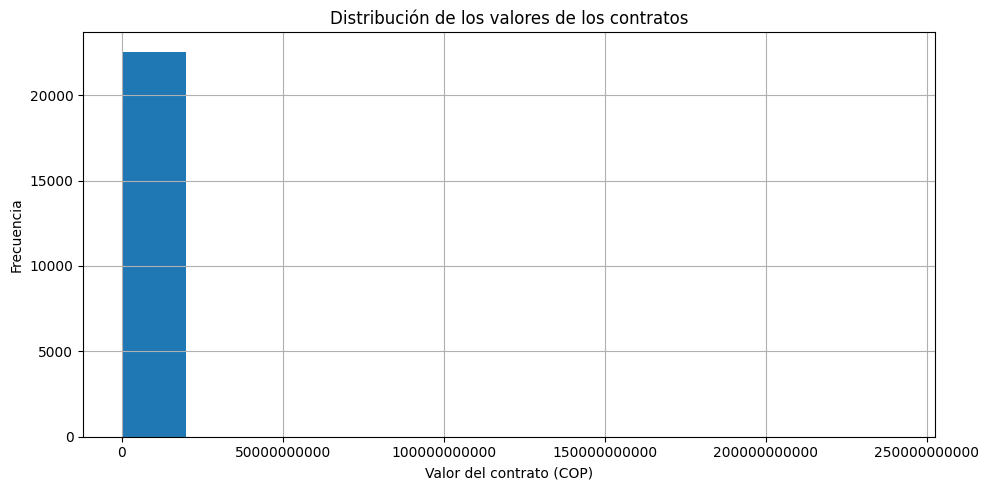

In [102]:

plt.figure(figsize=(10, 5))

dataset_limpio["valor_del_contrato"].dropna().hist(bins=12)

plt.title("Distribución de los valores de los contratos")
plt.xlabel("Valor del contrato (COP)")
plt.ylabel("Frecuencia")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()


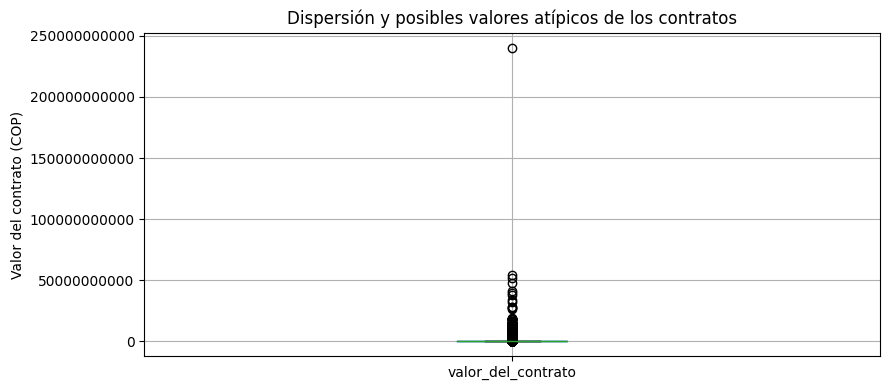

In [103]:

plt.figure(figsize=(9, 4))

dataset_limpio.boxplot(column="valor_del_contrato")

plt.title("Dispersión y posibles valores atípicos de los contratos")
plt.ylabel("Valor del contrato (COP)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()


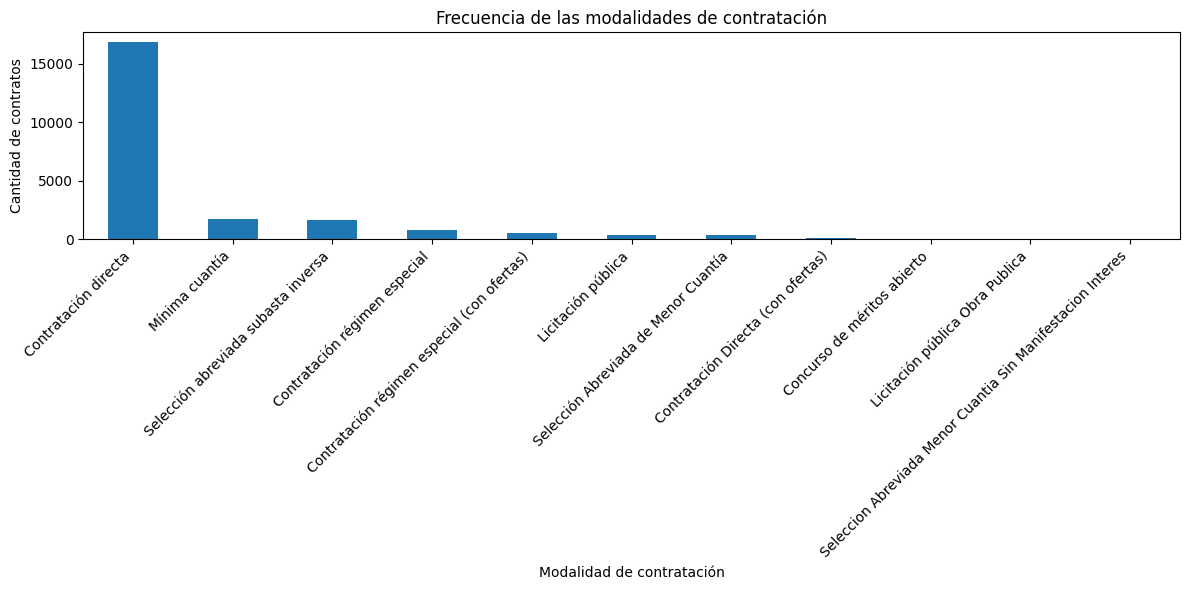

In [104]:

plt.figure(figsize=(12, 6))

frecuencia_modalidades.plot(kind="bar")

plt.title("Frecuencia de las modalidades de contratación")
plt.xlabel("Modalidad de contratación")
plt.ylabel("Cantidad de contratos")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [105]:

promedio_por_modalidad = (
    dataset_limpio
    .groupby("modalidad_de_contratacion_contrato")["valor_del_contrato"]
    .mean()
    .sort_values(ascending=False)
)

display(promedio_por_modalidad)


,valor_del_contrato
modalidad_de_contratacion_contrato,
Licitación pública Obra Publica,9.228006e+09
Licitación pública,6.554053e+09
Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes,2.179947e+09
Contratación régimen especial (con ofertas),1.303036e+09
Concurso de méritos abierto,7.367477e+08
Contratación Directa (con ofertas),4.612904e+08
Selección Abreviada de Menor Cuantía,4.280866e+08
Selección abreviada subasta inversa,2.907964e+08
Contratación régimen especial,1.442051e+08


In [106]:

mediana_por_modalidad = (
    dataset_limpio
    .groupby("modalidad_de_contratacion_contrato")["valor_del_contrato"]
    .median()
    .sort_values(ascending=False)
)

display(mediana_por_modalidad)


,valor_del_contrato
modalidad_de_contratacion_contrato,
Licitación pública,6.154198e+09
Licitación pública Obra Publica,3.209556e+09
Contratación régimen especial (con ofertas),1.399349e+09
Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes,8.221473e+08
Concurso de méritos abierto,3.450000e+08
Selección Abreviada de Menor Cuantía,2.890285e+08
Contratación Directa (con ofertas),2.121356e+08
Selección abreviada subasta inversa,7.210272e+07
Contratación régimen especial,3.060000e+07


## Historia de hallazgos

1. **Predominio de la contratación directa:** de los 22.562 registros analizados, 16.834 corresponden a contratación directa, aproximadamente el 74,6 %. Esto indica una alta concentración de registros en esta modalidad y justifica analizar su distribución por entidad y valor para apoyar las labores de seguimiento y control.

2. **Diferencia entre la media y la mediana:** el valor promedio de los contratos es de aproximadamente $253,6 millones, mientras que la mediana es de $20,2 millones. Esta diferencia muestra que algunos contratos de montos elevados aumentan considerablemente el promedio, por lo que la mediana representa mejor el valor central de los registros.

3. **Presencia de valores extremos:** el histograma y el diagrama de caja muestran una distribución muy sesgada y registros con valores considerablemente superiores al resto. Estos casos deben revisarse para determinar si corresponden a contratos legítimos de gran cuantía o a posibles inconsistencias de los datos.

4. **Diferencias entre modalidades:** las modalidades de licitación pública presentan promedios de valor contractual superiores a los de contratación directa y mínima cuantía. Esto sugiere que el valor de los contratos varía según la modalidad, aunque las diferencias deben interpretarse considerando la cantidad de registros de cada grupo y la presencia de valores extremos.

5. **Utilidad para el seguimiento de la contratación:** los resultados permiten identificar concentraciones por modalidad y posibles valores atípicos que las entidades responsables del seguimiento contractual podrían priorizar para su revisión. Estos patrones son señales para investigar, no pruebas de irregularidad o corrupción.

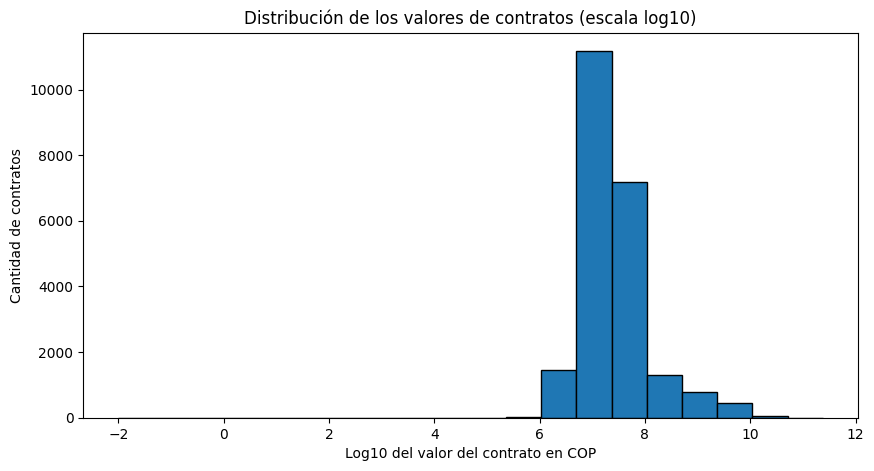

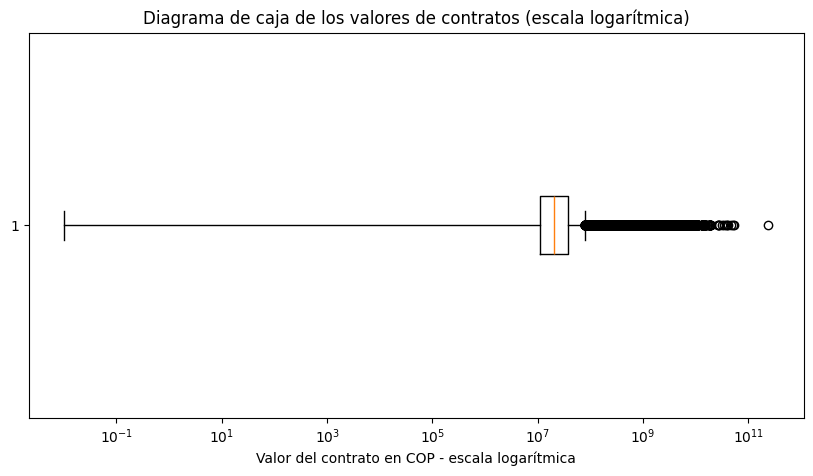

In [107]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Histograma en escala logarítmica
# Solo excluimos los ceros de este gráfico, no de la tabla.
valores = dataset_final.loc[
    dataset_final["valor_del_contrato"] > 0,
    "valor_del_contrato"
]

plt.figure(figsize=(10, 5))
plt.hist(np.log10(valores), bins=20, edgecolor="black")
plt.title("Distribución de los valores de contratos (escala log10)")
plt.xlabel("Log10 del valor del contrato en COP")
plt.ylabel("Cantidad de contratos")
plt.show()


# 2. Diagrama de caja en escala logarítmica
plt.figure(figsize=(10, 5))
plt.boxplot(valores, vert=False)
plt.xscale("log")
plt.title("Diagrama de caja de los valores de contratos (escala logarítmica)")
plt.xlabel("Valor del contrato en COP - escala logarítmica")
plt.show()


### Análisis de la distribución de los valores contractuales

El histograma en escala logarítmica muestra que la mayor concentración de contratos se encuentra aproximadamente entre 10 y 100 millones de pesos colombianos. También se observa una distribución asimétrica hacia los valores altos, debido a que existen contratos con montos considerablemente superiores a los de la mayoría.

El diagrama de caja permite identificar numerosos valores atípicos en la parte superior de la distribución. Estos registros corresponden a contratos cuyos valores se alejan del rango central y que podrían requerir una revisión adicional.

El uso de la escala logarítmica facilita la visualización de contratos con magnitudes diferentes. Sin embargo, los valores atípicos no deben eliminarse automáticamente, ya que pueden corresponder a contratos legítimos de gran cuantía.

**Conclusión:** la distribución de los valores contractuales es desigual. Para profundizar en el análisis, conviene examinar los contratos de mayor valor, las entidades responsables y las modalidades de contratación, con el fin de identificar patrones que ayuden a priorizar las revisiones de los organismos de control.

In [108]:

top_entidades = (
    dataset_final
    .groupby("nombre_entidad")["valor_del_contrato"]
    .agg(["count", "sum", "mean"])
    .sort_values("sum", ascending=False)
    .head(10)
)

top_entidades.columns = [
    "Cantidad de contratos",
    "Valor total contratado",
    "Valor promedio por contrato"
]

top_entidades


,Cantidad de contratos,Valor total contratado,Valor promedio por contrato
nombre_entidad,,,
MUNICIPIO DE PEREIRA- OFICIAL,9399,3.097239e+12,3.295286e+08
GOBERNACIÓN DE RISARALDA**,4892,1.957578e+12,4.001591e+08
SENA REGIONAL RISARALDA Grupo de Apoyo Administrativo Mixto//,3156,2.639887e+11,8.364662e+07
CORPORACION AUTONOMA REGIONAL DE RISARALDA,2092,1.356807e+11,6.485695e+07
POLICIA METROPOLITANA DE PEREIRA,119,4.672397e+10,3.926384e+08
EMPRESA DE DESARROLLO TERRITORIAL URBANO Y RURAL DE RISARALDA - EDUR,260,3.525859e+10,1.356100e+08
FISCALÍA GENERAL DE LA NACIÓN REGIONAL EJE CAFETERO,100,3.179863e+10,3.179863e+08
Rama Judicial  Dirección Seccional de Administración Judicial de Pereira,110,2.682219e+10,2.438381e+08
MEGABÚS S.A.,71,1.764121e+10,2.484677e+08


### Análisis de las entidades con mayor valor de contratación

El análisis de las diez entidades con mayor valor total contratado muestra que el Municipio de Pereira registra el mayor monto acumulado, con aproximadamente $3,10 billones y 9.399 contratos. En segundo lugar se encuentra la Gobernación de Risaralda, con cerca de $1,96 billones y 4.892 contratos.

Aunque el Municipio de Pereira tiene más contratos, la Gobernación presenta un valor promedio por contrato superior, de aproximadamente $400 millones frente a $330 millones. Por otra parte, el SENA Regional Risaralda registra 3.156 contratos, con un promedio aproximado de $83,6 millones.

Estos resultados evidencian diferencias importantes en el volumen y el valor de la contratación entre entidades. Por ello, se propone que los organismos de control utilicen estos patrones para priorizar análisis más detallados de los contratos de mayor cuantía, las modalidades de contratación y las inconsistencias detectadas durante la limpieza de datos. La concentración del gasto constituye un criterio de análisis, pero no es evidencia por sí sola de una irregularidad.

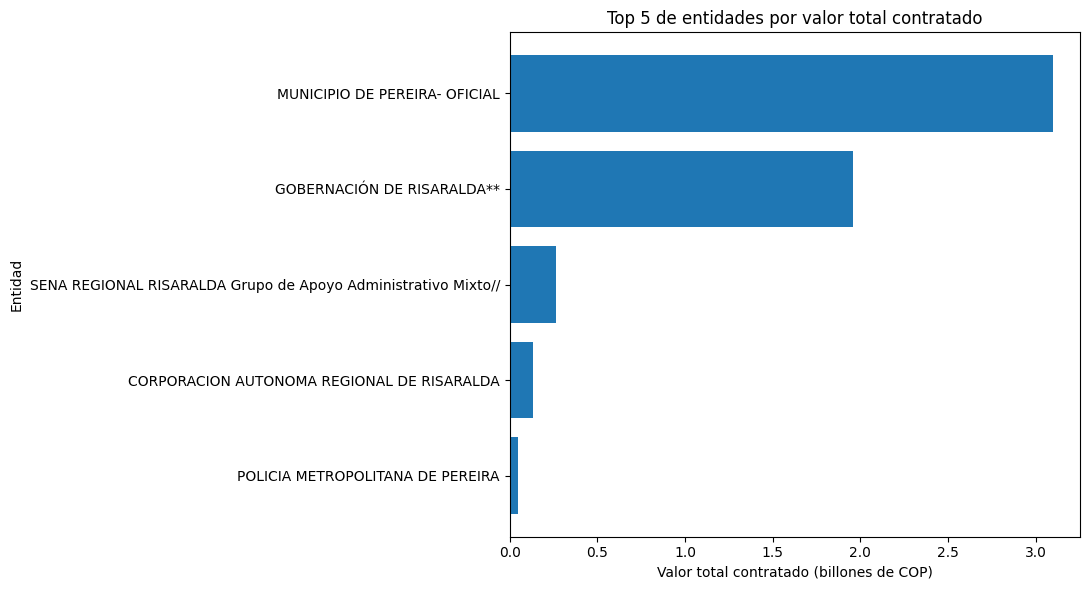

In [109]:

import matplotlib.pyplot as plt

top5 = top_entidades.head(5).copy()

# Convertir pesos a billones de COP para facilitar la lectura
top5["Valor en billones"] = top5["Valor total contratado"] / 1_000_000_000_000

plt.figure(figsize=(11, 6))
plt.barh(top5.index, top5["Valor en billones"])
plt.gca().invert_yaxis()
plt.title("Top 5 de entidades por valor total contratado")
plt.xlabel("Valor total contratado (billones de COP)")
plt.ylabel("Entidad")
plt.tight_layout()
plt.show()
